In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Titanic Survival: Exploratory Data Analysis
**Author:** ATHAMBAWA FATHIMA ANEESIYA | **Internship:** CodeAlpha Data Analytics

## 1. Introduction and Objective
The objective of this analysis is to identify the factors that influenced passenger survival on the Titanic.

## 2. Dataset Overview
The dataset contains 891 passengers and 12 variables, including age, sex, passenger class, fare, and survival status.

## 3. Questions to Answer
1. Did gender influence the likelihood of survival?
2. Did passenger class affect survival rates?
3. Is there a relationship between age and survival?
4. Is there a relationship between ticket fare and survival?

In [2]:
# Check the structure of the dataset
print(df.shape)
df.info()
df.describe()


(891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Missing Values and Duplicates
Next, we check for missing values and duplicate records that may need to be addressed before analysis.

In [3]:
# Check for missing values and duplicate records
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Duplicate rows: 0


## 5. Data Cleaning
Based on the quality check, the following cleaning decisions were made:

- **Age (177 missing, ~20%):** Filled with the median. The median is robust to outliers, so it represents a typical passenger better than the mean.
- **Cabin (687 missing, ~77%):** Dropped. Too many values are missing to fill reliably.
- **Embarked (2 missing):** Filled with the mode (most frequent port), since only two values are missing.

In [4]:
# Create a copy so the original data stays unchanged
df_clean = df.copy()

# Fill missing Age values with the median
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())

# Drop the Cabin column (too many missing values)
df_clean = df_clean.drop(columns=['Cabin'])

# Fill missing Embarked values with the most frequent port
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])

# Verify that no missing values remain
print(df_clean.isnull().sum())
print("Shape after cleaning:", df_clean.shape)

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64
Shape after cleaning: (891, 11)


## 6. Exploratory Analysis and Visualizations
We begin by calculating survival rates across key groups: gender, passenger class, and age group.


In [5]:
# Survival rate by gender
print("Survival rate by gender:")
print(df_clean.groupby('Sex')['Survived'].mean().round(3))

# Survival rate by passenger class
print("\nSurvival rate by passenger class:")
print(df_clean.groupby('Pclass')['Survived'].mean().round(3))

# Survival rate by age group
df_clean['AgeGroup'] = pd.cut(
    df_clean['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teen', 'Young Adult', 'Adult', 'Senior']
)
print("\nSurvival rate by age group:")
print(df_clean.groupby('AgeGroup', observed=True)['Survived'].mean().round(3))

Survival rate by gender:
Sex
female    0.742
male      0.189
Name: Survived, dtype: float64

Survival rate by passenger class:
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64

Survival rate by age group:
AgeGroup
Child          0.580
Teen           0.429
Young Adult    0.353
Adult          0.400
Senior         0.227
Name: Survived, dtype: float64


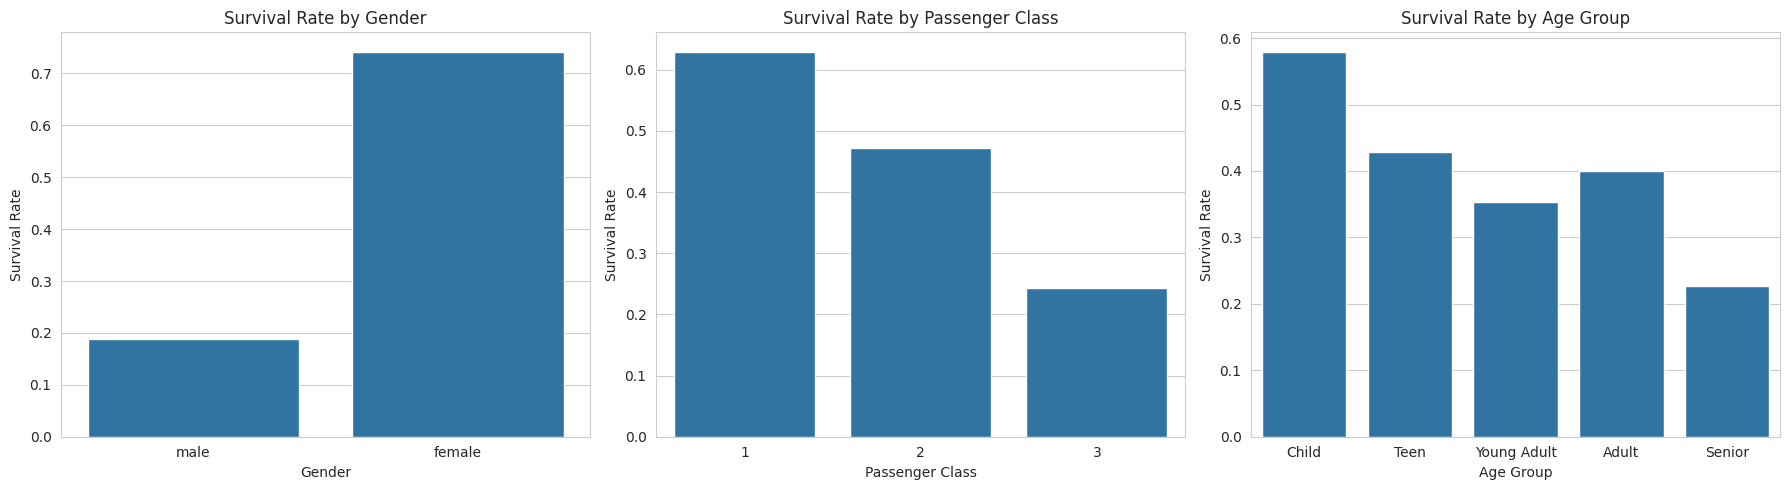

In [6]:
sns.set_style('whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Survival rate by gender
sns.barplot(x='Sex', y='Survived', data=df_clean, ax=axes[0], errorbar=None)
axes[0].set_title('Survival Rate by Gender')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Survival Rate')

# Chart 2: Survival rate by passenger class
sns.barplot(x='Pclass', y='Survived', data=df_clean, ax=axes[1], errorbar=None)
axes[1].set_title('Survival Rate by Passenger Class')
axes[1].set_xlabel('Passenger Class')
axes[1].set_ylabel('Survival Rate')

# Chart 3: Survival rate by age group
sns.barplot(x='AgeGroup', y='Survived', data=df_clean, ax=axes[2], errorbar=None)
axes[2].set_title('Survival Rate by Age Group')
axes[2].set_xlabel('Age Group')
axes[2].set_ylabel('Survival Rate')

plt.tight_layout()
plt.show()

### Key Insights
- **Gender:** Women survived at a much higher rate (~74%) than men (~19%).
- **Class:** Survival declined with passenger class. First class had the highest rate.
- **Age:** Children had the highest survival rate, consistent with "women and children first".

## 7. Hypothesis Testing
We test whether the patterns observed above are statistically significant (significance level: 0.05).

**Test 1 (Chi-square):** Is survival associated with gender?
- H0: Gender and survival are independent.
- H1: Gender and survival are associated.

**Test 2 (Chi-square):** Is survival associated with passenger class?
- H0: Passenger class and survival are independent.
- H1: Passenger class and survival are associated.

**Test 3 (Independent t-test):** Is the average fare different between survivors and non-survivors?
- H0: Mean fare is the same for both groups.
- H1: Mean fare differs between the groups.

In [7]:
from scipy.stats import chi2_contingency, ttest_ind

# Test 1: Gender vs Survival
table_sex = pd.crosstab(df_clean['Sex'], df_clean['Survived'])
chi2, p_sex, dof, expected = chi2_contingency(table_sex)
print(f"Gender vs Survival: chi2 = {chi2:.2f}, p-value = {p_sex:.2e}")

# Test 2: Passenger class vs Survival
table_class = pd.crosstab(df_clean['Pclass'], df_clean['Survived'])
chi2, p_class, dof, expected = chi2_contingency(table_class)
print(f"Class vs Survival: chi2 = {chi2:.2f}, p-value = {p_class:.2e}")

# Test 3: Fare of survivors vs non-survivors (Welch's t-test)
fare_survived = df_clean[df_clean['Survived'] == 1]['Fare']
fare_died = df_clean[df_clean['Survived'] == 0]['Fare']
t_stat, p_fare = ttest_ind(fare_survived, fare_died, equal_var=False)
print(f"Fare t-test: t = {t_stat:.2f}, p-value = {p_fare:.2e}")

print("\nMean fare (survived):", round(fare_survived.mean(), 2))
print("Mean fare (did not survive):", round(fare_died.mean(), 2))

Gender vs Survival: chi2 = 260.72, p-value = 1.20e-58
Class vs Survival: chi2 = 102.89, p-value = 4.55e-23
Fare t-test: t = 6.84, p-value = 2.70e-11

Mean fare (survived): 48.4
Mean fare (did not survive): 22.12


### Hypothesis Test Results
All three p-values are below 0.05, so we reject the null hypothesis in each case.

- **Gender** is significantly associated with survival.
- **Passenger class** is significantly associated with survival.
- **Fare** differs significantly between survivors and non-survivors.

Note: These tests show association, not causation. Fare and class are closely related, so their effects overlap.

## 8. Key Findings and Conclusion

**Answers to the questions:**
1. **Gender:** Women had a much higher survival rate (~74%) than men (~19%). The difference is statistically significant.
2. **Passenger class:** Survival declined with class: first class (~63%), second class (~47%), third class (~24%). The association is statistically significant.
3. **Age:** Children had the highest survival rate among the age groups, consistent with the "women and children first" policy.
4. **Fare:** Survivors paid a higher average fare (~48 vs ~22). The difference is statistically significant.

**Conclusion:**
Gender, passenger class, and age were the strongest factors associated with survival on the Titanic. Women, children, and first-class passengers had the best chances of survival.

**Limitatios:**
- Missing Age values were filled with the median, which may slightly distort the age analysis.
- The tests show association, not causation. Fare and class are related, so their effects overlap.